# Exploring ERA5 2 m temperature with xarray

[ERA5](https://www.ecmwf.int/en/forecasts/dataset/ecmwf-reanalysis-v5) is ECMWF's global
reanalysis of the atmosphere. This notebook uses the
[WeatherBench 2](https://weatherbench2.readthedocs.io/) copy, regridded to a coarse 64 × 32 grid (5.625° in longitude, about 5.81° in latitude, including the poles), 6-hourly, from 1959 to 2021, read directly from
cloud storage as Zarr.

Contents:

1. Opening the data lazily with xarray
2. A global temperature snapshot in °C
3. Time series for the grid cells containing Darmstadt and Reading
4. Monthly and seasonal climatology for Darmstadt (1991–2020), and the 1959–2021 trend
5. July 2019 temperature anomaly over Europe against the 1991–2020 WMO reference period

Each value is an average over a grid cell (several hundred kilometres across),
so results describe regions, not cities.

## 1. Opening the data

`xr.open_zarr` opens the data lazily: only metadata and coordinates are read, and values
are downloaded when a computation needs them. This makes a 63-year global dataset
(38 variables, about 188 million values for 2 m temperature alone) open in seconds.

A first check of the time coordinate shows the store covers 1959-01-02 to 2021-12-31,
despite the "1959-2022" in its name.

In [1]:
import pandas as pd
import numpy as np
import xarray as xr
from pathlib import Path
import matplotlib.pyplot as plt
from dask.diagnostics import ProgressBar

path = "gs://weatherbench2/datasets/era5/1959-2022-6h-64x32_equiangular_with_poles_conservative.zarr"
ds = xr.open_zarr(path, storage_options={"token": "anon"})
ds

<xarray.Dataset> Size: 81GB
Dimensions:                                           (time: 92040,
                                                       longitude: 64,
                                                       latitude: 32, level: 13)
Coordinates:
  * time                                              (time) datetime64[ns] 736kB ...
  * longitude                                         (longitude) float64 512B ...
  * latitude                                          (latitude) float64 256B ...
  * level                                             (level) int64 104B 50 ....
Data variables: (12/38)
    10m_u_component_of_wind                           (time, longitude, latitude) float32 754MB dask.array<chunksize=(100, 64, 32), meta=np.ndarray>
    10m_v_component_of_wind                           (time, longitude, latitude) float32 754MB dask.array<chunksize=(100, 64, 32), meta=np.ndarray>
    10m_wind_speed                                    (time, longitude, latitude) float32 754MB dask.array<chunksize=(100, 64, 32), meta=np.ndarray>
    2m_temperature                                    (time, longitude, latitude) float32 754MB dask.array<chunksize=(100, 64, 32), meta=np.ndarray>
    angle_of_sub_gridscale_orography                  (longitude, latitude) float32 8kB dask.array<chunksize=(64, 32), meta=np.ndarray>
    anisotropy_of_sub_gridscale_orography             (longitude, latitude) float32 8kB dask.array<chunksize=(64, 32), meta=np.ndarray>
    ...                                                ...
    type_of_high_vegetation                           (longitude, latitude) float32 8kB dask.array<chunksize=(64, 32), meta=np.ndarray>
    type_of_low_vegetation                            (longitude, latitude) float32 8kB dask.array<chunksize=(64, 32), meta=np.ndarray>
    u_component_of_wind                               (time, level, longitude, latitude) float32 10GB dask.array<chunksize=(100, 13, 64, 32), meta=np.ndarray>
    v_component_of_wind                               (time, level, longitude, latitude) float32 10GB dask.array<chunksize=(100, 13, 64, 32), meta=np.ndarray>
    vertical_velocity                                 (time, level, longitude, latitude) float32 10GB dask.array<chunksize=(100, 13, 64, 32), meta=np.ndarray>
    wind_speed                                        (time, level, longitude, latitude) float32 10GB dask.array<chunksize=(100, 13, 64, 32), meta=np.ndarray>

In [2]:
ds.time.values[[0, -1]]

array(['1959-01-02T00:00:00.000000000', '2021-12-31T18:00:00.000000000'],
      dtype='datetime64[ns]')

## 2. A global snapshot: 1 July 2020, 12:00 UTC

We select a single time step first, then convert from kelvin to °C and shift longitudes
from 0–360° to −180–180°, so that Europe and Africa sit in the centre of the map.
Selecting first matters with lazy data: only one time step is downloaded, instead of
transforming all 92,000 before discarding them.

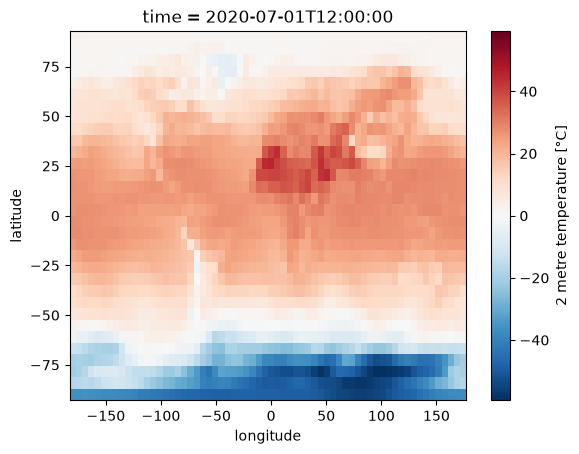

In [3]:
t2m_july = ds['2m_temperature'].sel(time='2020-07-01T12:00')
t2m_july = t2m_july - 273.15
t2m_july.attrs['units'] = '°C'
t2m_july = t2m_july.assign_coords(longitude=((t2m_july['longitude'] + 180)%360)-180).sortby("longitude")
t2m_july.plot(x="longitude", y="latitude")

The warmest areas are North Africa and the Middle East, as expected: it is northern
summer, and at 12:00 UTC it is early afternoon there, near the daily maximum. The
Americas, where it is night, appear cooler at this hour.

## 3. Time series: Darmstadt and Reading

We select the grid cells nearest to Darmstadt and Reading and average the 6-hourly
values into daily means for 2020, which removes the daily cycle and shows the
seasonal one.

Note: with a grid this coarse, the nearest grid point to Darmstadt lies about 195 km away,
and each value averages a region several hundred kilometres across. These series
describe the regions around the two cities, not the cities themselves.

In [4]:
#the grid cell containing Darmstadt
darmstadt = ds["2m_temperature"].sel(latitude=49.9, longitude=8.65, method="nearest")

#the grid cell containing Reading
reading = ds["2m_temperature"].sel(latitude=51.4, longitude=360-0.97, method="nearest")

In [5]:
def resampled_mean_celsius(series, start, end, time_frame):
    """Mean 2 m temperature in °C over regular time bins, between start and end."""
    series = series.sel(time=slice(start, end))
    series = series - 273.15
    series = series.resample(time=time_frame).mean()
    series.attrs['units'] = '°C'
    return series

reading_daily = resampled_mean_celsius(reading, "2020-01-01", "2020-12-31", "1D")
darmstadt_daily = resampled_mean_celsius(darmstadt, "2020-01-01", "2020-12-31", "1D")

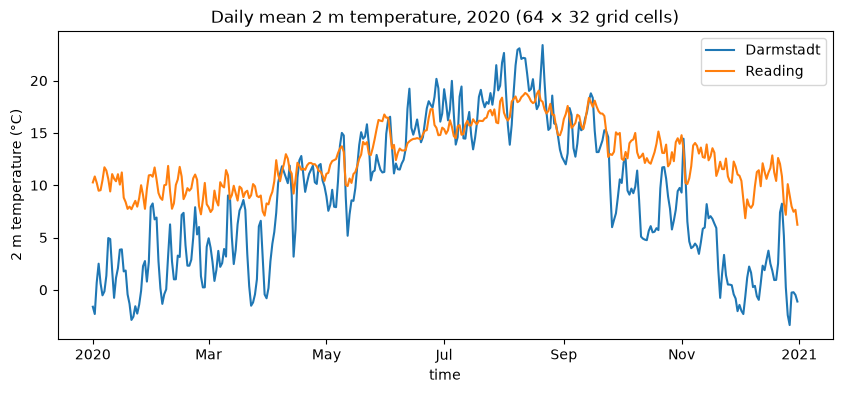

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))     

darmstadt_daily.plot(ax=ax, label="Darmstadt")   
reading_daily.plot(ax=ax, label="Reading")       

ax.set_ylabel("2 m temperature (°C)")
ax.set_title("Daily mean 2 m temperature, 2020 (64 × 32 grid cells)")
ax.legend()

In [7]:
START, END = "2020-01-01", "2020-12-31"

darmstadt_monthly = resampled_mean_celsius(darmstadt, START, END, "1MS")
reading_monthly = resampled_mean_celsius(reading, START, END, "1MS")

darmstadt_amplitude = float(darmstadt_monthly.max() - darmstadt_monthly.min())
reading_amplitude = float(reading_monthly.max() - reading_monthly.min())

pd.DataFrame(
    {"Seasonal amplitude (°C)": [darmstadt_amplitude, reading_amplitude]},
    index=["Darmstadt", "Reading"],
).round(1)

,Seasonal amplitude (°C)
Darmstadt,17.6
Reading,8.3


Darmstadt's seasonal amplitude (17.6 °C, warmest minus coldest month) is about twice
Reading's (8.3 °C). Reading has a maritime climate: the ocean's high heat capacity damps
both summer heat and winter cold, and its grid cell includes part of the sea, which
damps the cycle further. Darmstadt's cell is entirely inland, with a more continental
climate.

## 4. Climatology and long-term trend

A climatology is the average value for each calendar month (or season) over a long
reference period; here the WMO standard 1991–2020. Because the data is chunked by time,
extracting one grid point over many years means downloading every global chunk, so the
1959–2021 series (used later for the long-term trend analysis) is downloaded once and cached locally as Zarr.

1. Compute the monthly mean temperature for each calendar month over 1991–2020, and
   compare it with the monthly means of 2020 in the Darmstadt grid cell.
2. Repeat the comparison by season.
3. Show the differences from the normal as bar plots.

In [8]:
def load_or_download(selection, path, name):
    """Load `selection` from a local Zarr cache at `path`, downloading and caching it if missing."""
    if path.exists():
        return xr.open_zarr(path)[name].load()

    with ProgressBar():
        data = selection.load()
    dataset = data.to_dataset(name=name)
    for variable in dataset.variables.values():
        variable.encoding = {}
    dataset.to_zarr(path)
    return data

def climatology_by_timespan_celsius(series, timespan):
    """Calculate the climatology for a given timespan in Celsius."""
    series_timespan_climatology = series.groupby(timespan).mean()
    series_timespan_climatology = series_timespan_climatology - 273.15
    series_timespan_climatology.attrs["units"] = "°C"
    return series_timespan_climatology

def plot_against_normal(ax, x, normal, observed, title, xlabel):
    """Plot observed values against a climatological normal on the given axes."""
    ax.plot(x, normal, marker="o", label="1991-2020 normal")
    ax.plot(x, observed, marker="x", label="2020")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("2 m temperature (°C)")
    ax.set_title(title)
    ax.legend()


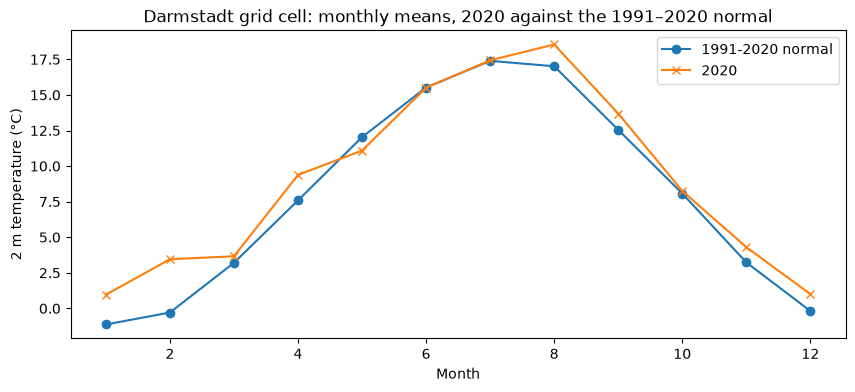

In [9]:
darmstadt_1959_2021 = load_or_download(darmstadt, Path("data/darmstadt_1959_2021.zarr"), "2m_temperature")
darmstadt_1991_2020 = darmstadt_1959_2021.sel(time=slice("1991", "2020"))

darmstadt_monthly_climatology = climatology_by_timespan_celsius(darmstadt_1991_2020, 'time.month')

fig, ax = plt.subplots(figsize=(10, 4))
plot_against_normal(ax, darmstadt_monthly_climatology.month, darmstadt_monthly_climatology, darmstadt_monthly, "Darmstadt grid cell: monthly means, 2020 against the 1991–2020 normal", "Month")

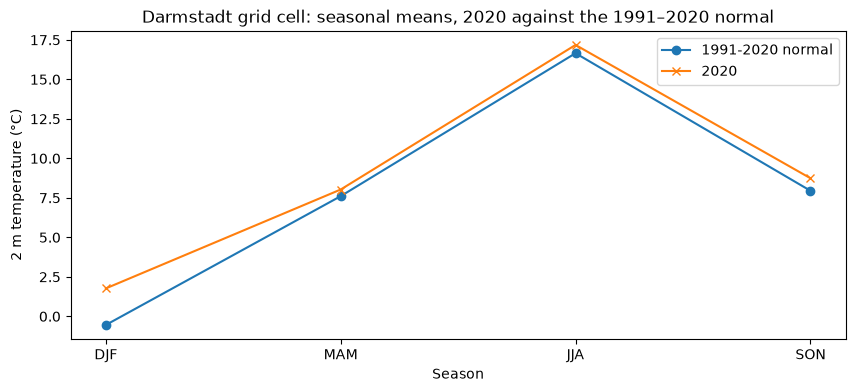

In [10]:
SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]

darmstadt_seasonal_climatology = climatology_by_timespan_celsius(darmstadt_1991_2020, 'time.season')
darmstadt_seasonal_climatology = darmstadt_seasonal_climatology.sel(season=SEASON_ORDER)

darmstadt_seasonal_2020 = climatology_by_timespan_celsius(darmstadt_1991_2020.sel(time='2020'), 'time.season')
darmstadt_seasonal_2020 = darmstadt_seasonal_2020.sel(season=SEASON_ORDER)

fig, ax = plt.subplots(figsize=(10, 4))     
plot_against_normal(ax, darmstadt_seasonal_climatology.season, darmstadt_seasonal_climatology, darmstadt_seasonal_2020, "Darmstadt grid cell: seasonal means, 2020 against the 1991–2020 normal", "Season")

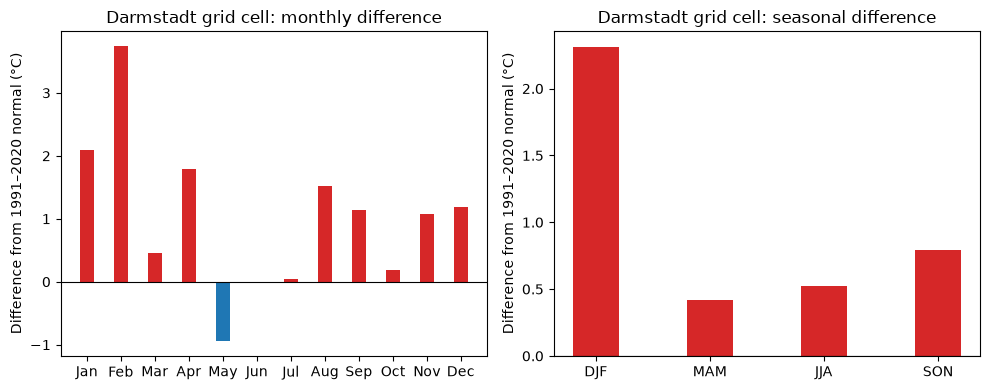

In [11]:
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

darmstadt_seasonal_difference = darmstadt_seasonal_2020 - darmstadt_seasonal_climatology
darmstadt_seasonal_difference.attrs['units'] = '°C'

darmstadt_monthly_difference = darmstadt_monthly.groupby("time.month").mean() - darmstadt_monthly_climatology
darmstadt_monthly_difference.attrs['units'] = '°C'

def plot_difference_bars(ax, x, differences, title, xlabels):
    """Bar plot of differences from the normal: red above, blue below."""
    colours = ["tab:red" if d > 0 else "tab:blue" for d in differences.values]
    ax.bar(x, differences, 0.4, color=colours)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xticks(x, xlabels)
    ax.set_ylabel("Difference from 1991–2020 normal (°C)")

fig, ax = plt.subplots(1,2, figsize=(10, 4))     
plot_difference_bars(ax[0], range(12), darmstadt_monthly_difference, "Darmstadt grid cell: monthly difference", MONTH_NAMES)
plot_difference_bars(ax[1], range(4), darmstadt_seasonal_difference, "Darmstadt grid cell: seasonal difference", SEASON_ORDER)
fig.tight_layout()

In the Darmstadt grid cell, 2020 was warmer than the 1991–2020 normal in 10 of 12
months, most strongly in February (+3.7 °C) and winter (Jan, Feb and Dec 2020, +2.3 °C). A single year cannot show a long-term
trend, since year-to-year variability is large, but a consistently warm year is in line
with the warming observed across Europe in recent decades.

### 4b. Annual mean temperature, 1959–2021
We analyse the annual mean temperature trend in Darmstadt in the period 1959–2021.
Annual means are computed from the 6-hourly series for the Darmstadt grid cell, and a
straight line is fitted to them by least squares (`np.polyfit`) to estimate the
long-term trend.

In [12]:
annual = darmstadt_1959_2021.resample(time="1YS").mean() - 273.15
years = annual.time.dt.year.values
slope, intercept = np.polyfit(years, annual.values, 1)
print(f"Trend: {slope * 10:+.2f} °C per decade")

Trend: +0.33 °C per decade


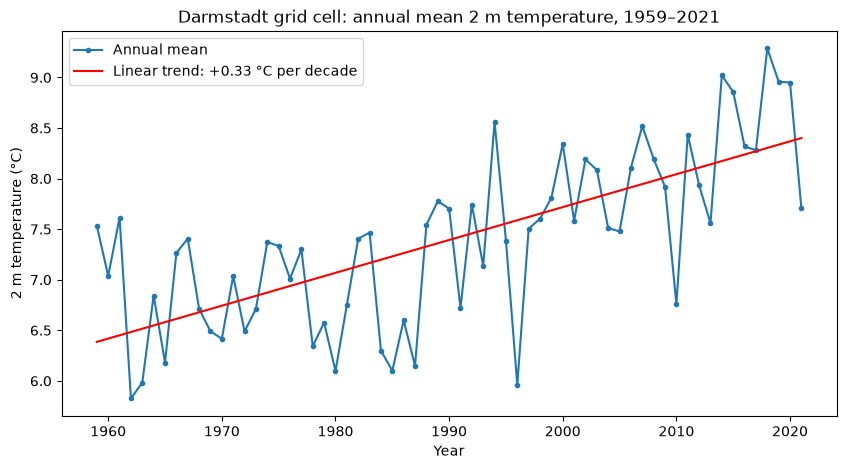

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(years, annual, marker="o", markersize=3, label="Annual mean")
ax.plot(years, slope * years + intercept, color="red",
        label=f"Linear trend: {slope * 10:+.2f} °C per decade")
ax.set_xlabel("Year")
ax.set_ylabel("2 m temperature (°C)")
ax.set_title("Darmstadt grid cell: annual mean 2 m temperature, 1959–2021")
ax.legend()

Annual means for the Darmstadt grid cell show a linear warming trend of +0.33 °C per
decade over 1959–2021, about +2 °C over the whole period. The trend is descriptive:
it is a least-squares line fitted to annual means, with no significance test.

## 5. July 2019 temperature anomaly over Europe

An anomaly is the difference from the normal: here, the July 2019 mean minus the mean of
all Julys in 1991–2020. July 2019 is chosen for its European heatwave (the dataset ends in
2021, so 2022 is not available). The colour map is centred on 0, so warmer and colder
areas appear in red and blue respectively.

In [14]:
t2m = ds['2m_temperature'].sel(time = slice("1991", "2021"))
julys = t2m.sel(time=t2m.time.dt.month==7)

julys_path = Path("./data/2m_temperature_global_july_1991_2021.zarr")
julys_1991_2021 = load_or_download(julys, julys_path, "2m_temperature_global_july")

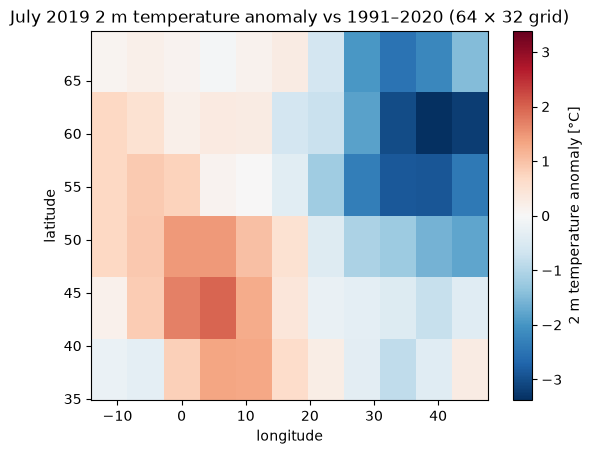

In [15]:
july_normal = julys_1991_2021.sel(time=slice("1991", "2020")).mean("time")
july_2019 = julys_1991_2021.sel(time="2019").mean("time")
anomaly = july_2019 - july_normal
anomaly = anomaly.assign_coords(longitude=((anomaly['longitude'] + 180)%360)-180).sortby("longitude")
anomaly.attrs["units"] = "°C"
anomaly.attrs["long_name"] = "2 m temperature anomaly"
anomaly_europe = anomaly.sel(latitude=slice(35,72), longitude=slice(-15,45))
mesh = anomaly_europe.plot(x="longitude", y="latitude", cmap="RdBu_r", center=0)
mesh.axes.set_title("July 2019 2 m temperature anomaly vs 1991–2020 (64 × 32 grid)")

plt.gcf().savefig("figures/july_2019_anomaly.png", dpi=150, bbox_inches="tight")

July 2019 was warmer than normal over western and central Europe, most strongly around
France (up to about +2 °C), while the north-east (the Baltic region and western Russia) was colder than normal by up to about 3 °C.

## Conclusions and limitations

Findings:

- **Seasonal cycle:** Darmstadt's seasonal amplitude in 2020 (17.6 °C) is about twice
  Reading's (8.3 °C), consistent with Reading's maritime climate.
- **2020 against the 1991–2020 normal:** in the Darmstadt grid cell, 10 of 12 months
  were warmer than normal, most strongly February (+3.7 °C).
- **Long-term trend:** annual means in the Darmstadt grid cell rose by about
  +0.33 °C per decade over 1959–2021 (about +2 °C in total).
- **July 2019 anomaly:** warmer than normal over western and central Europe (up to
  about +2 °C around France) and colder in the north-east (down to about −3 °C).

Limitations:

- The 64 × 32 grid averages over regions several hundred kilometres wide, so results
  describe regions, not specific locations.
- Monthly means dilute short extremes such as heatwaves.
- A single year cannot show a long-term trend; 2020 is also part of its own reference
  period.
- The trend is a descriptive least-squares fit, without a significance test.
- The WeatherBench 2 store ends in 2021, despite "2022" in its name.